**Contributors: Anshuman · Inka · Juan Diego**

# Exploratory Analysis

Local companion analysis. Reproduce the pipeline first; the main optimization notebook is standalone.

week
1    1062
2    1053
3    1338
4    1330
Name: forecast_units, dtype: int64

,demand,release,opening,gap
sku,,,,
B400,370,378,57,65
F300,724,744,111,131
G700,773,636,105,-32
H600,1035,804,167,-64
J100,491,498,90,97
J200,415,292,45,-78
P500,482,480,90,88
S800,493,504,89,100


,store_name,shelf_capacity_units,delivery_cost_per_visit,truck_capacity_units,demand,shelf_to_horizon_demand
store_id,,,,,,
S11,Nashua,240,240,420,331,0.725076
S06,Portland ME,280,320,420,381,0.734908
S08,Burlington VT,220,380,420,294,0.748299
S12,Portsmouth,230,300,420,307,0.749186
S07,Manchester NH,260,260,420,341,0.762463
S01,Boston Back Bay,520,180,420,672,0.773810
S03,Providence,360,220,420,456,0.789474
S02,Cambridge,380,150,420,481,0.790021
S05,Hartford,340,240,420,430,0.790698


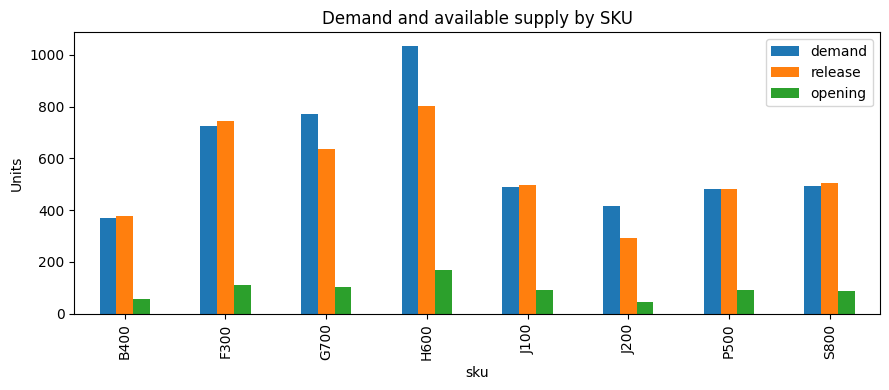

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
root=Path.cwd().parent
D={p.stem:pd.read_csv(p) for p in (root/'data/raw').glob('*.csv')}
weekly=D['demand_forecast'].groupby('week').forecast_units.sum()
supply=pd.concat([D['demand_forecast'].groupby('sku').forecast_units.sum().rename('demand'),D['dc_availability'].groupby('sku').units_available.sum().rename('release'),D['opening_inventory'].groupby('sku').on_hand_units.sum().rename('opening')],axis=1)
supply['gap']=supply.release+supply.opening-supply.demand
display(weekly);display(supply)
stores=D['stores'].set_index('store_id').join(D['demand_forecast'].groupby('store_id').forecast_units.sum().rename('demand'))
stores['shelf_to_horizon_demand']=stores.shelf_capacity_units/stores.demand
display(stores.sort_values('shelf_to_horizon_demand'))
fig,ax=plt.subplots(figsize=(9,4));supply[['demand','release','opening']].plot.bar(ax=ax)
ax.set_title('Demand and available supply by SKU');ax.set_ylabel('Units');plt.tight_layout();plt.show()
